# 公开数据中的城市街道调查

**学习问题：只能调查一部分街道时，先去哪里？**

这是一个已经跑通的公开数据项目。你可以先阅读保留的输出，再逐格运行。数据来自西雅图 Project Sidewalk 和 OpenStreetMap，不需要 API Key 或 GPU。

模型预测的是“是否有符合定义的公开障碍记录”，不是今日路况、老人真实出行时间或修路效果。完整解释见 `LEARNING_GUIDE.md`。

本 Notebook 展示并复核实际训练结果；完整训练由 `python analysis.py` 执行。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT / "urban_access_learning"
assert (ROOT / "results/predictions.csv").exists(), "请先运行 analysis.py"
streets = pd.read_csv(ROOT / "data/processed/streets.csv")
pred = pd.read_csv(ROOT / "results/predictions.csv")
metrics = pd.read_csv(ROOT / "results/model_metrics.csv")
policy = pd.read_csv(ROOT / "results/policy_summary.csv")
quality = json.loads((ROOT / "results/data_quality.json").read_text())
print(f"原始道路：{quality['raw_streets']:,}")
print(f"聚合标注：{quality['raw_clusters']:,}")
print(f"设施地点：{quality['raw_places']:,}")
print(f"正式评估道路：{len(pred):,}")

原始道路：21,224
聚合标注：127,773
设施地点：4,344
正式评估道路：6,500


## 1. 先认识一条街道

一行是一个路段。`target=1` 表示存在合格公开障碍记录；`target=0` 表示没有检索到合格记录，不能直接解释为没有障碍。

`audit_count>=2` 是样本筛选条件，不是模型输入，也不代表两位独立调查者。

In [2]:
cols = ["street_edge_id", "region_name", "way_type", "length_m",
        "audit_count", "target", "cohort"]
display(streets[cols].head(8).round(1))
display(streets.groupby("cohort").agg(
    streets=("street_edge_id", "size"),
    with_records=("target", "sum"),
    record_share=("target", "mean"),
).round(3))

,street_edge_id,region_name,way_type,length_m,audit_count,target,cohort
0,9575,Yesler Terrace,residential,60.0,2,1,True
1,5,Matthews Beach,secondary,201.2,4,0,True
2,6,Matthews Beach,secondary,61.8,3,0,True
3,7,Matthews Beach,secondary,184.7,3,0,True
4,8,Matthews Beach,secondary,372.2,5,1,True
5,9,Matthews Beach,secondary,199.9,2,0,True
6,10,Matthews Beach,secondary,222.3,3,0,True
7,11,Matthews Beach,secondary,210.4,3,0,True


,streets,with_records,record_share
cohort,,,
False,1416,779,0.550
True,6500,3633,0.559


## 2. 附近有什么

这里计算的是街道中点附近的设施与直线距离。它反映邻近性，不能自动解释为步行可达性。`health` 还包括药房，不仅是医院。

In [3]:
display(streets[["street_edge_id", "health_within_400m",
                 "transit_within_400m", "nearest_health_m"]].head(8).round(1))
display(streets[["length_m", "nearest_health_m", "health_within_400m"]]
        .describe().round(1))

,street_edge_id,health_within_400m,transit_within_400m,nearest_health_m
0,9575,2,25,190.1
1,5,0,6,1579.0
2,6,0,4,1820.6
3,7,0,4,1739.1
4,8,0,7,1218.0
5,9,0,6,1421.2
6,10,0,4,2080.8
7,11,0,4,2251.2


,length_m,nearest_health_m,health_within_400m
count,7916.0,7916.0,7916.0
mean,134.7,739.2,0.6
std,100.5,494.5,1.5
min,15.1,14.5,0.0
25%,80.4,369.6,0.0
50%,102.1,635.8,0.0
75%,190.4,1003.8,1.0
max,3021.8,3146.7,28.0


## 3. 历史照片的时间

数据今天下载，并不说明照片今天拍摄。聚合标签的平均图像日期也不是一次新调查日期。下面的数字帮助判断能把结果说到什么程度。

In [4]:
years = pd.read_csv(ROOT / "results/image_years.csv")
display(years)
old_share = years.loc[years.image_year <= 2021, "clusters"].sum() / years.clusters.sum()
print(f"合格样本关联记录中，平均图像年份不晚于 2021 年的比例：{old_share:.1%}")

,image_year,clusters
0,2007,12
1,2008,27
2,2009,2
3,2011,165
4,2012,17
5,2013,26
6,2014,203
7,2015,152
8,2016,164
9,2017,180


合格样本关联记录中，平均图像年份不晚于 2021 年的比例：94.4%


## 4. AI 的输入与验证

模型输入来自几何与设施，不包含障碍数量、答案、调查次数和区域编号。下图左侧的五种颜色表示五个地理测试区域。每次完整留出一个区域，并删除距测试路段中点不足 500 米的训练样本。

右侧是将这些隐藏答案的测试道路评分后，按各区约 10% 名额选出的调查候选。它是一项回溯检索实验。

模型输入： length_m, sinuosity, end_degree_mean, health_within_400m, transit_within_400m, grocery_within_400m, park_within_400m, school_within_400m, community_within_400m, library_within_400m, nearest_health_m, way_type


,fold,train,test,buffer_excluded,min_train_test_distance_m,train_prevalence,test_prevalence
0,0,5315,1107,78,502.404,0.555,0.570
1,1,4743,1629,128,502.949,0.605,0.419
2,2,5112,1230,158,506.069,0.539,0.621
3,3,5734,731,35,502.579,0.571,0.464
4,4,4512,1803,185,500.340,0.510,0.674


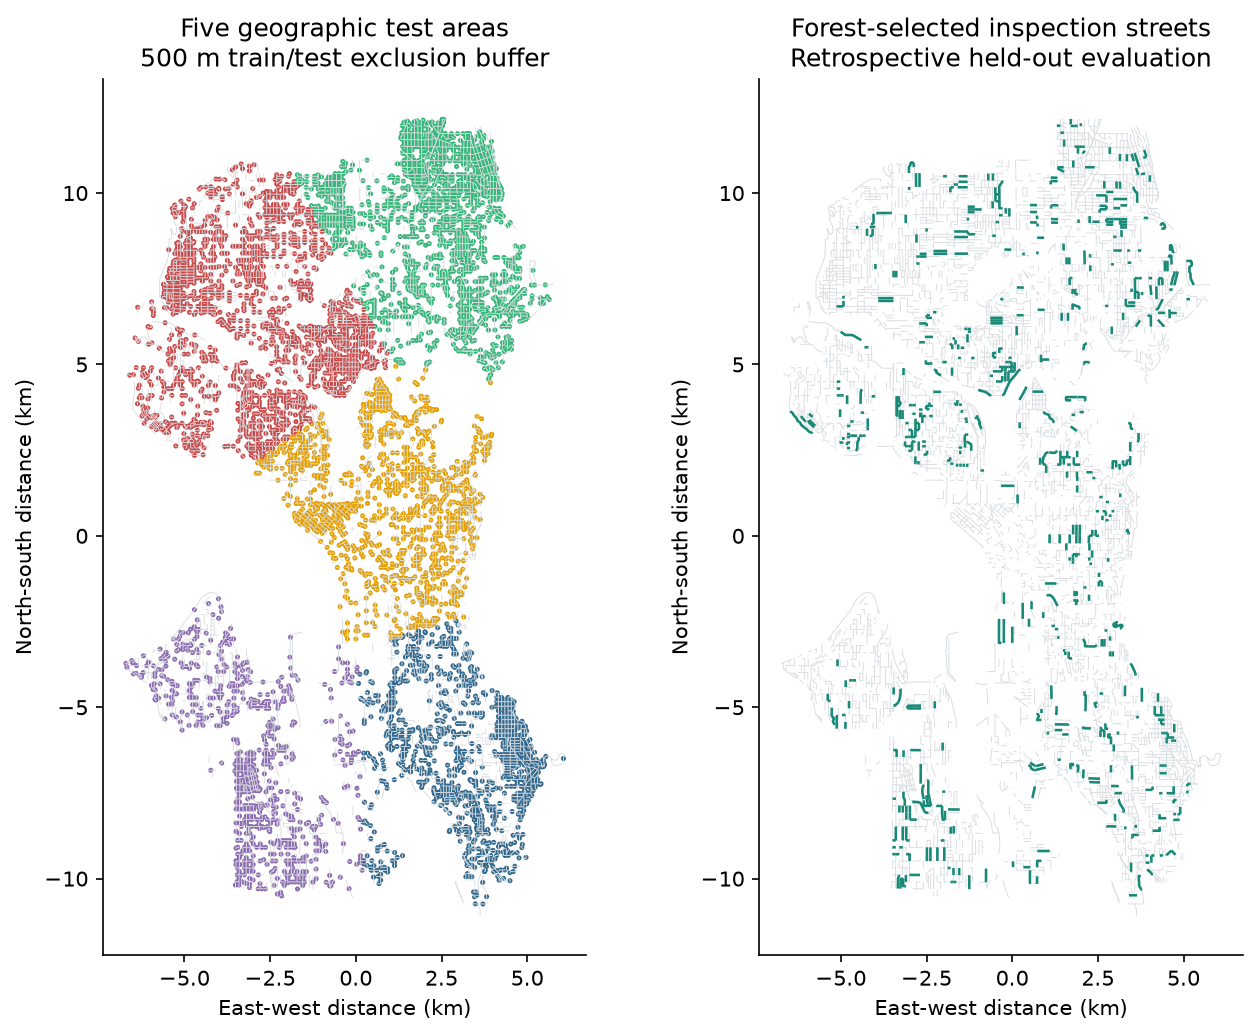

In [5]:
config = json.loads((ROOT / "results/run_config.json").read_text())
print("模型输入：", ", ".join(config["features"]))
display(pd.read_csv(ROOT / "results/split_checks.csv").round(3))
display(Image(filename=str(ROOT / "results/study_map.png"), width=850))

## 5. 模型成绩与决策成绩分开看

左图的 AP 衡量排序效果，它不是准确率。右图比较相同路段名额下找到记录的比例；随机方案误差条是 200 次随机抽样的第 5—95 百分位。

请特别看“优先选择长路段”的简单规则。一个 AI 方法优于随机，并不意味着它优于合理的简单方法。

,split,model,n,ap,roc_auc,brier
5,random,logistic,6500,0.6835,0.6499,0.2290
11,random,forest,6500,0.7181,0.6976,0.2174
17,spatial,logistic,6500,0.6132,0.5598,0.2486
23,spatial,forest,6500,0.6261,0.5864,0.2514


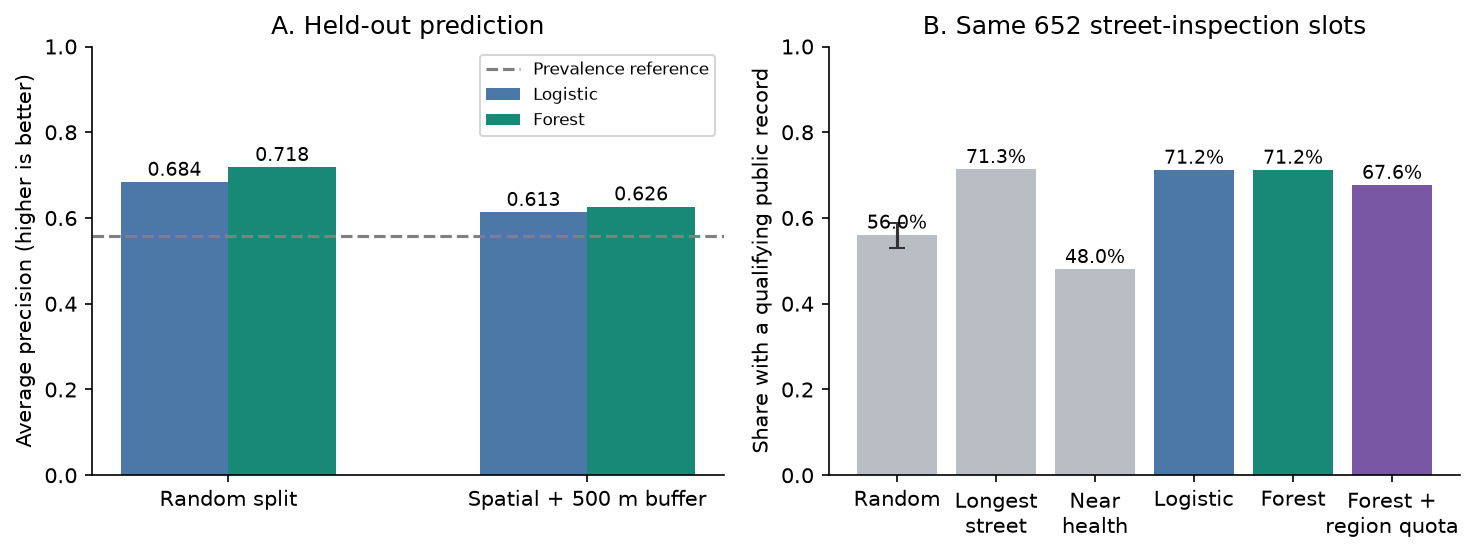

In [6]:
display(metrics.loc[metrics.fold == "pooled", ["split", "model", "n", "ap", "roc_auc", "brier"]].round(4))
display(Image(filename=str(ROOT / "results/model_and_policy.png"), width=1000))

## 6. 用真实名单重算一次

下面不用报告的汇总数字，直接连接选中名单和测试答案，自己计算分子与分母。研究结果应该能追溯到这一步。

In [7]:
selected = pd.read_csv(ROOT / "results/selected_streets_10pct.csv")
joined = selected.merge(pred[["street_edge_id", "target", "length_m"]],
                        on="street_edge_id", validate="many_to_one")
summary = joined.groupby("strategy").agg(
    inspection_slots=("street_edge_id", "size"),
    qualifying_records=("target", "sum"),
    mean_selected_length_m=("length_m", "mean"),
)
summary["record_share"] = summary.qualifying_records / summary.inspection_slots
display(summary.round(4))
rf = summary.loc["forest"]
random = policy.loc[(policy.strategy == "random") & np.isclose(policy.fraction, .1)].iloc[0]
print(f"森林相对随机抽样的平均记录数量差：{rf.qualifying_records - random.mean_found:.2f}")
print("这不是新增发现、实际修复数或出行改善人数。")

,inspection_slots,qualifying_records,mean_selected_length_m,record_share
strategy,,,,
forest,652,464,200.1684,0.7117
forest_region_quota,652,441,199.7464,0.6764
logistic,652,464,286.8939,0.7117
longest,652,465,335.2551,0.7132
near_health,652,313,127.4925,0.4801


森林相对随机抽样的平均记录数量差：98.75
这不是新增发现、实际修复数或出行改善人数。


## 7. 改变目标会发生什么

“森林＋社区名额”先轮流给各社区一个名额，再在社区内部选模型评分最高的路段。下面比较其记录比例与社区覆盖。

社区覆盖是各测试区域覆盖比例的平均值，不是被服务居民比例；没有人口和需求数据，不能直接断言哪种方案对弱势人群更公平。

In [8]:
view = policy.loc[np.isclose(policy.fraction, .1),
                  ["strategy", "budget", "mean_found", "precision",
                   "macro_region_coverage", "mean_selected_length_m"]]
display(view.round(4))
print("同名额不等于同工时：请比较最后一列的道路长度。")

,strategy,budget,mean_found,precision,macro_region_coverage,mean_selected_length_m
6,forest,652,464.00,0.7117,0.8109,200.1684
7,forest_region_quota,652,441.00,0.6764,1.0000,199.7464
8,logistic,652,464.00,0.7117,0.9305,286.8939
9,longest,652,465.00,0.7132,0.9254,335.2551
10,near_health,652,313.00,0.4801,0.6804,127.4925
11,random,652,365.25,0.5602,0.9077,136.4892


同名额不等于同工时：请比较最后一列的道路长度。


## 8. 一个可以立即动手的练习

把下面 `budget_fraction` 从 0.10 改成 0.05 或 0.20，观察结论是否一致。三个预算已在完整实验中运行，下面切换展示现成结果，不假装重新训练。

再写一句解释：为什么某个方法的检出比例更高，却可能需要更多调查时间？

In [9]:
budget_fraction = 0.10
display(policy.loc[np.isclose(policy.fraction, budget_fraction),
                   ["strategy", "budget", "mean_found", "precision",
                    "macro_region_coverage", "mean_selected_length_m"]].round(4))

,strategy,budget,mean_found,precision,macro_region_coverage,mean_selected_length_m
6,forest,652,464.00,0.7117,0.8109,200.1684
7,forest_region_quota,652,441.00,0.6764,1.0000,199.7464
8,logistic,652,464.00,0.7117,0.9305,286.8939
9,longest,652,465.00,0.7132,0.9254,335.2551
10,near_health,652,313.00,0.4801,0.6804,127.4925
11,random,652,365.25,0.5602,0.9077,136.4892


## 9. 记录定义改变，样本也会改变

确认计数门槛越高，“有合格记录”的含义越严格。下面仅描述不同定义下的样本与标签比例，没有重新训练所有定义的模型。

练习：只改一个门槛，避免同时改变多个条件后无法解释差异。

In [10]:
display(pd.read_csv(ROOT / "results/definition_sensitivity.csv").round(4))

,min_agree,min_audits,streets,positive,record_prevalence
0,1,1,7908,5003,0.6327
1,1,2,6500,4144,0.6375
2,1,3,3124,1978,0.6332
3,2,1,7908,4411,0.5578
4,2,2,6500,3633,0.5589
5,2,3,3124,1686,0.5397
6,3,1,7908,3664,0.4633
7,3,2,6500,3018,0.4643
8,3,3,3124,1389,0.4446


## 10. 你能解释到什么程度

完成后，尝试回答：

1. 为什么没有合格记录不能等于没有问题？
2. 为什么需要空间验证和简单基线？
3. 为什么社区名额规则并不自动证明人群公平？
4. 为什么模型特征重要性不能解释为因果关系？
5. 如果想把这个项目扩展成博士申请研究，你会新增什么独立证据？

下一项建议：固定模型，比较 0、250、500、1,000 米缓冲，并控制训练样本量。完整计划见学习路线最后一节。

数据来源及许可见 `DATA_CARD.md`。代码和文稿为 AI 辅助制作；申请时应准确描述你实际掌握、复核和完成的工作。